In [ ]:
# ================================
# PHASE 1: Environment Setup
# ================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow Version:", tf.__version__)


TensorFlow Version: 2.19.0


In [ ]:
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [ ]:
import os
drive_path = "/content/drive/MyDrive"
os.listdir(drive_path)


['IMG-20240708-WA0001.jpg',
 'Classroom',
 'PRACT 4.docx',
 'Screenshot (8).png',
 'impact-of-internet-of-things-on-society-IJERTCONV5IS03020.pdf',
 'IMG-20241010-WA0035.jpg',
 'rakshit_ladda.pdf',
 'SAMEEKSHA-IOT (2).pptx',
 'SAMEEKSHA-IOT (1).pptx',
 'SAMEEKSHA-IOT.pptx',
 'Copy of ELECTRICALAPPROVAL.gdoc',
 'Screenshot 2024-11-08 113926.png',
 'eee assingment.pdf',
 'Document from Rakshit Ladda.pdf',
 'BT24ECE063. RAKSHIT LADDA.pdf',
 'SAMKEESHA IOT funal paper.pdf',
 'Screenshot_2025-01-19-21-04-30-312_com.phonepe.app.jpg',
 'Screenshot_2025-01-25-10-17-57-042_com.miui.gallery.jpg',
 'Screenshot_2025-04-19-16-14-39-959_com.phonepe.app.jpg',
 'Untitled spreadsheet.gsheet',
 'Colab Notebooks',
 'RAKSHIT_LADDA(BT24CSD066).png',
 'BT24CSD066(RAKSHIT LADDA).png',
 'RAKSHIT LADDA(BT24CSD066) LOGO.jpg',
 ' BRANCH_CHANGE_APPLICATION.gdoc',
 'BT24CSD066(RAKSHIT LADDA)MINDEASE.pdf',
 'Screenshot 2025-09-05 121312.png',
 'TF_2025_BROCHURE EVE1.pdf',
 '50_Startups (1).csv.gsheet',
 '50_Startup

In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/Original Image (1).zip"
extract_path = "/content/mendeley_fruit_dataset"

# Create extraction folder if it doesn't exist
os.makedirs(extract_path, exist_ok=True)

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("✅ Dataset extracted successfully!")


✅ Dataset extracted successfully!


In [ ]:
import os

dataset_root = "/content/drive/MyDrive/Final_Dataset"  # change if needed

all_folders = sorted(os.listdir(dataset_root))
all_folders


['test', 'train']

In [ ]:
import os

train_dir = "/content/drive/MyDrive/Final_Dataset/train"  # adjust if needed
sorted(os.listdir(train_dir))


['Fresh', 'Rotten']

In [ ]:
import os

train_dir = "/content/drive/MyDrive/Final_Dataset/train"

sorted(os.listdir(train_dir))


['Fresh', 'Rotten']

In [ ]:
import os

for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)
    indent = ' ' * 4 * level
    print(f"{indent}{os.path.basename(root)}/")

NameError: name 'extract_path' is not defined

In [ ]:
import os
import shutil

source_dir = "/content/mendeley_fruit_dataset/Original Image"
binary_dir = "/content/mendeley_binary_dataset"

fresh_dir = os.path.join(binary_dir, "Fresh")
rotten_dir = os.path.join(binary_dir, "Rotten")

os.makedirs(fresh_dir, exist_ok=True)
os.makedirs(rotten_dir, exist_ok=True)


In [ ]:
for folder in os.listdir(source_dir):
    folder_path = os.path.join(source_dir, folder)

    if not os.path.isdir(folder_path):
        continue

    # Decide label from folder name
    if folder.startswith("Fresh"):
        target_dir = fresh_dir
    elif folder.startswith("Rotten"):
        target_dir = rotten_dir
    else:
        continue

    # Copy all images
    for img_name in os.listdir(folder_path):
        src_img = os.path.join(folder_path, img_name)
        dst_img = os.path.join(target_dir, f"{folder}_{img_name}")
        shutil.copy(src_img, dst_img)


In [ ]:
print("Fresh images:", len(os.listdir(fresh_dir)))
print("Rotten images:", len(os.listdir(rotten_dir)))


Fresh images: 1600
Rotten images: 1600


In [ ]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    binary_dir,
    validation_split=0.2,
    subset="training",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    binary_dir,
    validation_split=0.2,
    subset="validation",
    seed=42,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

# Store class_names before normalization
class_names = train_ds.class_names

Found 3200 files belonging to 2 classes.
Using 2560 files for training.
Found 3200 files belonging to 2 classes.
Using 640 files for validation.


In [ ]:
normalization_layer = tf.keras.layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
val_ds   = val_ds.map(lambda x, y: (normalization_layer(x), y))


In [ ]:
# ================================
# Baseline CNN Model
# ================================

model = keras.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='sigmoid')  # Binary classification
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
EPOCHS = 10

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS
)

Epoch 1/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 401s 5s/step - accuracy: 0.6235 - loss: 0.8375 - val_accuracy: 0.8453 - val_loss: 0.3504
Epoch 2/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 404s 5s/step - accuracy: 0.8390 - loss: 0.3544 - val_accuracy: 0.8391 - val_loss: 0.3715
Epoch 3/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 411s 5s/step - accuracy: 0.8519 - loss: 0.3326 - val_accuracy: 0.8859 - val_loss: 0.2883
Epoch 4/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 441s 5s/step - accuracy: 0.8857 - loss: 0.2630 - val_accuracy: 0.9031 - val_loss: 0.2523
Epoch 5/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 438s 5s/step - accuracy: 0.9137 - loss: 0.2102 - val_accuracy: 0.9000 - val_loss: 0.2651
Epoch 6/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 416s 5s/step - accuracy: 0.9402 - loss: 0.1559 - val_accuracy: 0.8828 - val_loss: 0.3081
Epoch 7/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 407s 5s/step - accuracy: 0.9500 - loss: 0.1324 - val_accuracy: 0.9109 - val_loss: 0.2518
Epoch 8/10
80/80 ━━━━━━━━━━━━━━━━━━━━ 397s 5s/step - accuracy: 0.9580 - loss: 0.1111 - val_accuracy: 0.9141 - v

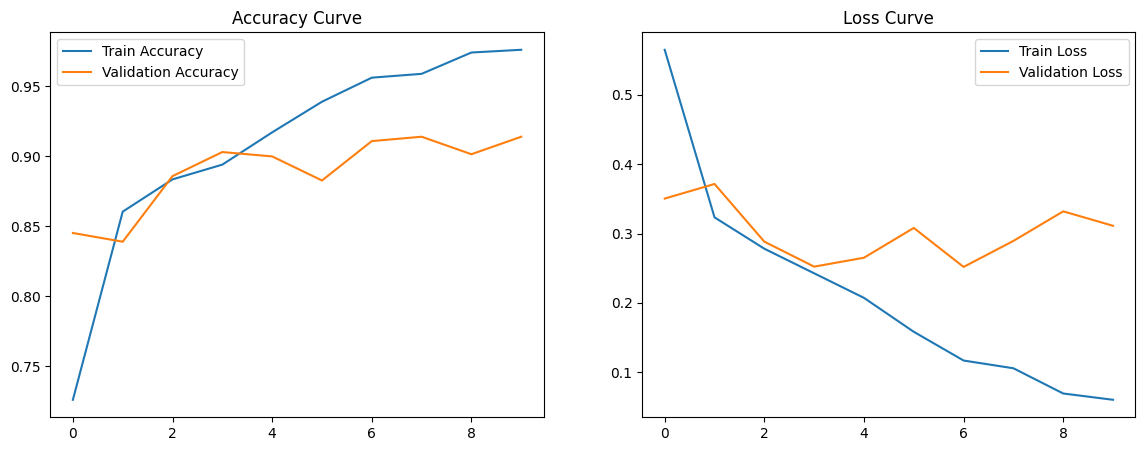

In [ ]:
 # ================================
# Plot Accuracy & Loss
# ================================

plt.figure(figsize=(14,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title("Accuracy Curve")

# Loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Loss Curve")

plt.show()


In [ ]:
# ================================
# Predictions
# ================================

y_true = np.concatenate([y for x, y in val_ds], axis=0)

y_pred_probs = model.predict(val_ds)
y_pred = (y_pred_probs > 0.5).astype(int)


20/20 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step


In [ ]:
class_names = train_ds.class_names

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names
))

              precision    recall  f1-score   support

       Fresh       0.52      0.58      0.54       318
      Rotten       0.53      0.47      0.49       322

    accuracy                           0.52       640
   macro avg       0.52      0.52      0.52       640
weighted avg       0.52      0.52      0.52       640



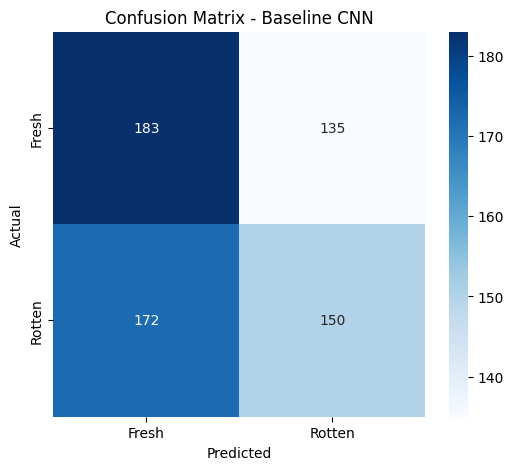

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names,
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Baseline CNN")
plt.show()


In [ ]:
MODEL_DIR = "/content/drive/MyDrive/Fruit_CNN_Models"


In [ ]:
import os
os.makedirs(MODEL_DIR, exist_ok=True)


In [ ]:
# ================================
# Save Phase 1 Baseline Model
# ================================

PHASE_1_MODEL_PATH = MODEL_DIR + "/phase1_baseline_cnn.keras"

model.save(PHASE_1_MODEL_PATH)

print("✅ Phase 1 Baseline Model Saved at:")
print(PHASE_1_MODEL_PATH)


✅ Phase 1 Baseline Model Saved at:
/content/drive/MyDrive/Fruit_CNN_Models/phase1_baseline_cnn.keras


In [ ]:
# ================================
# Load Phase 1 Model
# ================================

from tensorflow import keras

PHASE_1_MODEL_PATH = "/content/drive/MyDrive/Fruit_CNN_Models/phase1_baseline_cnn.keras"

model = keras.models.load_model(PHASE_1_MODEL_PATH)

print("✅ Phase 1 Baseline Model Loaded Successfully")


✅ Phase 1 Baseline Model Loaded Successfully


In [ ]:
# ================================
# Early Stopping Callback
# ================================

early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',      # Watch validation loss
    patience=3,              # Stop after 3 non-improving epochs
    restore_best_weights=True
)


In [ ]:
# ================================
# Train Model (Phase 2.1)
# ================================

EPOCHS = 30  # Upper bound; early stopping decides actual stop

history_es = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)


Epoch 1/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 415s 5s/step - accuracy: 0.9936 - loss: 0.0182 - val_accuracy: 0.9047 - val_loss: 0.5186
Epoch 2/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 404s 5s/step - accuracy: 0.9769 - loss: 0.0601 - val_accuracy: 0.9172 - val_loss: 0.4137
Epoch 3/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 395s 5s/step - accuracy: 0.9936 - loss: 0.0245 - val_accuracy: 0.9172 - val_loss: 0.4989
Epoch 4/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 406s 5s/step - accuracy: 0.9968 - loss: 0.0111 - val_accuracy: 0.9234 - val_loss: 0.4407
Epoch 5/30
80/80 ━━━━━━━━━━━━━━━━━━━━ 442s 5s/step - accuracy: 0.9993 - loss: 0.0050 - val_accuracy: 0.9250 - val_loss: 0.4374


In [ ]:
# ================================
# Save Phase 2.1 Model
# ================================

PHASE_2_1_MODEL_PATH = MODEL_DIR + "/phase2_early_stopping.keras"
model.save(PHASE_2_1_MODEL_PATH)

print("✅ Phase 2.1 Model Saved")


✅ Phase 2.1 Model Saved


In [ ]:
# ================================
# Save Phase 2.1 History
# ================================

import pickle

PHASE_2_1_HISTORY_PATH = MODEL_DIR + "/phase2_early_stopping_history.pkl"

with open(PHASE_2_1_HISTORY_PATH, "wb") as f:
    pickle.dump(history_es.history, f)

print("✅ Phase 2.1 Training History Saved")


✅ Phase 2.1 Training History Saved


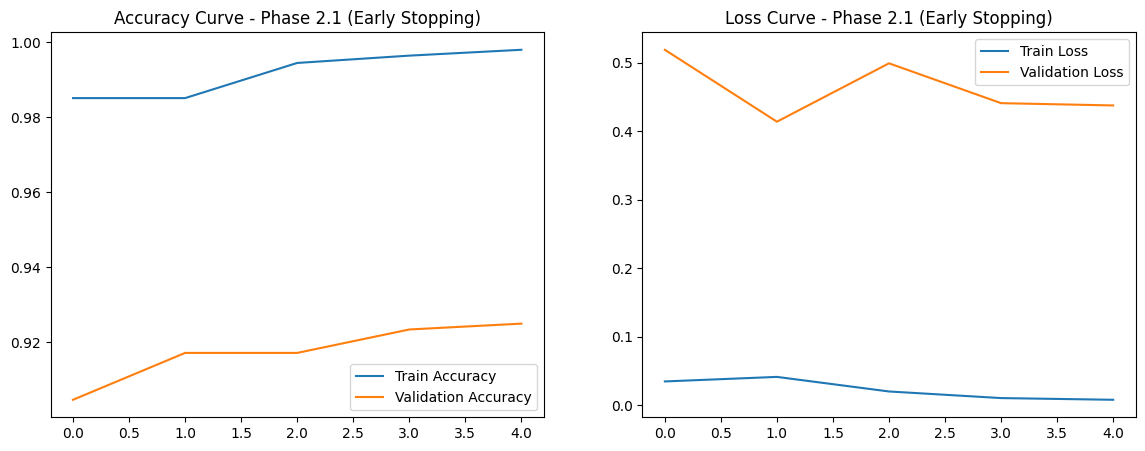

In [ ]:
# ================================
# Plot Accuracy & Loss (Phase 2.1)
# ================================

plt.figure(figsize=(14,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history_es.history['accuracy'], label='Train Accuracy')
plt.plot(history_es.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title("Accuracy Curve - Phase 2.1 (Early Stopping)")

# Loss
plt.subplot(1,2,2)
plt.plot(history_es.history['loss'], label='Train Loss')
plt.plot(history_es.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Loss Curve - Phase 2.1 (Early Stopping)")

plt.show()



In [ ]:
# ================================
# Evaluation - Phase 2.1
# ================================

y_true = np.concatenate([y for x, y in val_ds], axis=0)

y_pred_probs = model.predict(val_ds)
y_pred = (y_pred_probs > 0.5).astype(int)

from sklearn.metrics import classification_report, confusion_matrix

print(classification_report(y_true, y_pred, target_names=class_names))


20/20 ━━━━━━━━━━━━━━━━━━━━ 44s 2s/step
              precision    recall  f1-score   support

       Fresh       0.50      0.46      0.48       318
      Rotten       0.50      0.54      0.52       322

    accuracy                           0.50       640
   macro avg       0.50      0.50      0.50       640
weighted avg       0.50      0.50      0.50       640



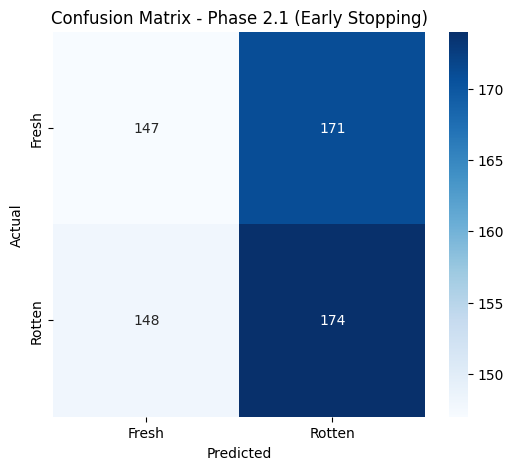

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d',
            xticklabels=class_names,
            yticklabels=class_names,
            cmap='Blues')
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix - Phase 2.1 (Early Stopping)")
plt.show()


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/Merged_Fruit_Dataset"

for split in ["train", "test"]:
    for cls in ["Fresh", "Rotten"]:
        os.makedirs(os.path.join(BASE_DIR, split, cls), exist_ok=True)


In [ ]:
import os
drive_path = "/content/drive/MyDrive"
os.listdir(drive_path)


['Colab Notebooks',
 'IMG-20240708-WA0001.jpg',
 'Classroom',
 'PRACT 4.docx',
 'Screenshot (8).png',
 'impact-of-internet-of-things-on-society-IJERTCONV5IS03020.pdf',
 'IMG-20241010-WA0035.jpg',
 'rakshit_ladda.pdf',
 'SAMEEKSHA-IOT (2).pptx',
 'SAMEEKSHA-IOT (1).pptx',
 'SAMEEKSHA-IOT.pptx',
 'Copy of ELECTRICALAPPROVAL.gdoc',
 'Screenshot 2024-11-08 113926.png',
 'eee assingment.pdf',
 'Document from Rakshit Ladda.pdf',
 'BT24ECE063. RAKSHIT LADDA.pdf',
 'SAMKEESHA IOT funal paper.pdf',
 'Screenshot_2025-01-19-21-04-30-312_com.phonepe.app.jpg',
 'Screenshot_2025-01-25-10-17-57-042_com.miui.gallery.jpg',
 'Screenshot_2025-04-19-16-14-39-959_com.phonepe.app.jpg',
 'Untitled spreadsheet.gsheet',
 'RAKSHIT_LADDA(BT24CSD066).png',
 'BT24CSD066(RAKSHIT LADDA).png',
 'RAKSHIT LADDA(BT24CSD066) LOGO.jpg',
 ' BRANCH_CHANGE_APPLICATION.gdoc',
 'BT24CSD066(RAKSHIT LADDA)MINDEASE.pdf',
 'Screenshot 2025-09-05 121312.png',
 'TF_2025_BROCHURE EVE1.pdf',
 '50_Startups (1).csv.gsheet',
 '50_Startup

In [ ]:
import zipfile
import os

# Paths
ORIGINAL_ZIP = "/content/drive/MyDrive/Original Image (1).zip"
AUG_ZIP = "/content/drive/MyDrive/Augmented Image (1).zip"

ORIGINAL_EXTRACT = "/content/drive/MyDrive/Original_Dataset"
AUG_EXTRACT = "/content/drive/MyDrive/Augmented_Dataset"

os.makedirs(ORIGINAL_EXTRACT, exist_ok=True)
os.makedirs(AUG_EXTRACT, exist_ok=True)

# Unzip original
with zipfile.ZipFile(ORIGINAL_ZIP, 'r') as zip_ref:
    zip_ref.extractall(ORIGINAL_EXTRACT)

# Unzip augmented
with zipfile.ZipFile(AUG_ZIP, 'r') as zip_ref:
    zip_ref.extractall(AUG_EXTRACT)

print("✅ Both datasets extracted")


✅ Both datasets extracted


In [ ]:
print("Original dataset folders:")
print(os.listdir(ORIGINAL_EXTRACT))

print("\nAugmented dataset folders:")
print(os.listdir(AUG_EXTRACT))


Original dataset folders:
['Original Image']

Augmented dataset folders:
['Augmented Image']


In [ ]:
def count_images(base_path):
    for root, dirs, files in os.walk(base_path):
        if len(files) > 0:
            print(f"{root} -> {len(files)} images")

print("📊 Original Dataset:")
count_images(ORIGINAL_EXTRACT)

print("\n📊 Augmented Dataset:")
count_images(AUG_EXTRACT)


📊 Original Dataset:
/content/drive/MyDrive/Original_Dataset/Original Image/FreshApple -> 200 images
/content/drive/MyDrive/Original_Dataset/Original Image/FreshBanana -> 200 images
/content/drive/MyDrive/Original_Dataset/Original Image/FreshGrape -> 200 images
/content/drive/MyDrive/Original_Dataset/Original Image/FreshGuava -> 200 images
/content/drive/MyDrive/Original_Dataset/Original Image/FreshJujube -> 200 images
/content/drive/MyDrive/Original_Dataset/Original Image/FreshOrange -> 200 images
/content/drive/MyDrive/Original_Dataset/Original Image/FreshPomegranate -> 200 images
/content/drive/MyDrive/Original_Dataset/Original Image/FreshStrawberry -> 200 images
/content/drive/MyDrive/Original_Dataset/Original Image/RottenApple -> 200 images
/content/drive/MyDrive/Original_Dataset/Original Image/RottenBanana -> 200 images
/content/drive/MyDrive/Original_Dataset/Original Image/RottenGrape -> 200 images
/content/drive/MyDrive/Original_Dataset/Original Image/RottenGuava -> 200 images
/

In [ ]:
import os
import shutil
import random


In [ ]:
# ================================
# Base paths
# ================================

ORIGINAL_BASE = "/content/drive/MyDrive/Original_Dataset/Original Image"
AUGMENTED_BASE = "/content/drive/MyDrive/Augmented_Dataset/Augmented Image"

FINAL_BASE = "/content/drive/MyDrive/Final_Dataset"

TRAIN_DIR = os.path.join(FINAL_BASE, "train")
TEST_DIR  = os.path.join(FINAL_BASE, "test")

# Create final folders
for split in ["train", "test"]:
    for cls in ["Fresh", "Rotten"]:
        os.makedirs(os.path.join(FINAL_BASE, split, cls), exist_ok=True)

print("✅ Final_Dataset folder structure created")


✅ Final_Dataset folder structure created


In [ ]:
def get_freshness(folder_name):
    if folder_name.startswith("Fresh"):
        return "Fresh"
    elif folder_name.startswith("Rotten"):
        return "Rotten"
    else:
        raise ValueError(f"Unknown class folder: {folder_name}")


In [ ]:
random.seed(42)
TRAIN_RATIO = 0.8

for folder in os.listdir(ORIGINAL_BASE):
    folder_path = os.path.join(ORIGINAL_BASE, folder)

    if not os.path.isdir(folder_path):
        continue

    label = get_freshness(folder)
    images = os.listdir(folder_path)

    random.shuffle(images)

    split_index = int(len(images) * TRAIN_RATIO)
    train_imgs = images[:split_index]
    test_imgs  = images[split_index:]

    # Copy training images
    for img in train_imgs:
        shutil.copy(
            os.path.join(folder_path, img),
            os.path.join(TRAIN_DIR, label, f"{folder}_{img}")
        )

    # Copy test images
    for img in test_imgs:
        shutil.copy(
            os.path.join(folder_path, img),
            os.path.join(TEST_DIR, label, f"{folder}_{img}")
        )

print("✅ Original dataset split into train and test safely")


✅ Original dataset split into train and test safely


In [ ]:
for folder in os.listdir(AUGMENTED_BASE):
    folder_path = os.path.join(AUGMENTED_BASE, folder)

    if not os.path.isdir(folder_path):
        continue

    label = get_freshness(folder)
    images = os.listdir(folder_path)

    for img in images:
        shutil.copy(
            os.path.join(folder_path, img),
            os.path.join(TRAIN_DIR, label, f"{folder}_{img}")
        )

print("✅ Augmented images added to TRAIN set only")


✅ Augmented images added to TRAIN set only


In [ ]:
def count_images(path):
    for split in ["train", "test"]:
        for cls in ["Fresh", "Rotten"]:
            count = len(os.listdir(os.path.join(path, split, cls)))
            print(f"{split}/{cls}: {count} images")

print("📊 Final Dataset Summary:")
count_images(FINAL_BASE)


📊 Final Dataset Summary:
train/Fresh: 6541 images
train/Rotten: 6141 images
test/Fresh: 416 images
test/Rotten: 432 images


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
import matplotlib.pyplot as plt
import numpy as np
import os


In [ ]:
# ================================
# Dataset paths
# ================================

DATASET_PATH = "/content/drive/MyDrive/Final_Dataset"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42


In [ ]:
train_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_PATH, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

test_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_PATH, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print("Class Names:", class_names)


Found 12655 files belonging to 2 classes.
Found 640 files belonging to 2 classes.
Class Names: ['Fresh', 'Rotten']


In [ ]:
normalization_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds  = test_ds.map(lambda x, y: (normalization_layer(x), y))

train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds  = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)


In [ ]:
# ================================
# Baseline CNN Model (unchanged)
# ================================

model = keras.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# ================================
# Train CNN on Final_Dataset
# ================================

EPOCHS = 10
history_c1 = model.fit(
    train_ds,
    validation_data=test_ds
    epochs=EPOCHS
)


Epoch 1/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 1747s 4s/step - accuracy: 0.7753 - loss: 0.5383 - val_accuracy: 0.8344 - val_loss: 0.3675
Epoch 2/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 1450s 4s/step - accuracy: 0.8888 - loss: 0.2574 - val_accuracy: 0.9141 - val_loss: 0.2244
Epoch 3/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 1435s 4s/step - accuracy: 0.9242 - loss: 0.1895 - val_accuracy: 0.9281 - val_loss: 0.1894
Epoch 4/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 1413s 4s/step - accuracy: 0.9474 - loss: 0.1351 - val_accuracy: 0.9312 - val_loss: 0.1634
Epoch 5/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 1418s 4s/step - accuracy: 0.9667 - loss: 0.0893 - val_accuracy: 0.9500 - val_loss: 0.1188
Epoch 6/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 1418s 4s/step - accuracy: 0.9788 - loss: 0.0630 - val_accuracy: 0.9531 - val_loss: 0.1204
Epoch 7/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 1415s 4s/step - accuracy: 0.9809 - loss: 0.0510 - val_accuracy: 0.9281 - val_loss: 0.2173
Epoch 8/10
396/396 ━━━━━━━━━━━━━━━━━━━━ 1419s 4s/step - accuracy: 0.9835 - loss: 0.0506 - 

In [ ]:
MODEL_DIR = "/content/drive/MyDrive/Fruit_CNN_Models"
os.makedirs(MODEL_DIR, exist_ok=True)

PHASE_C1_MODEL_PATH = MODEL_DIR + "/phaseC1_cnn_augmented.keras"
model.save(PHASE_C1_MODEL_PATH)

print("✅ Phase C1 model saved")


✅ Phase C1 model saved


In [ ]:
import pickle

PHASE_C1_HISTORY_PATH = MODEL_DIR + "/phaseC1_history.pkl"

with open(PHASE_C1_HISTORY_PATH, "wb") as f:
    pickle.dump(history_c1.history, f)

print("✅ Phase C1 training history saved")


✅ Phase C1 training history saved


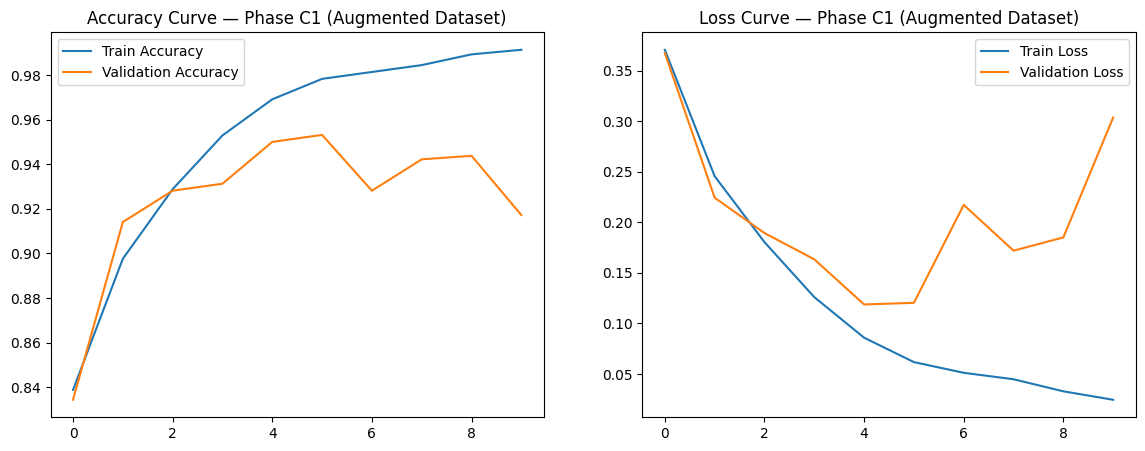

In [ ]:
plt.figure(figsize=(14,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history_c1.history['accuracy'], label='Train Accuracy')
plt.plot(history_c1.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title("Accuracy Curve — Phase C1 (Augmented Dataset)")

# Loss
plt.subplot(1,2,2)
plt.plot(history_c1.history['loss'], label='Train Loss')
plt.plot(history_c1.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Loss Curve — Phase C1 (Augmented Dataset)")

plt.show()


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


In [ ]:
# Predictions
y_true = np.concatenate([y for x, y in test_ds], axis=0)

y_pred_probs = model.predict(test_ds)
y_pred = (y_pred_probs > 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=class_names))


20/20 ━━━━━━━━━━━━━━━━━━━━ 20s 995ms/step
              precision    recall  f1-score   support

       Fresh       0.86      0.99      0.92       320
      Rotten       0.99      0.84      0.91       320

    accuracy                           0.92       640
   macro avg       0.93      0.92      0.92       640
weighted avg       0.93      0.92      0.92       640



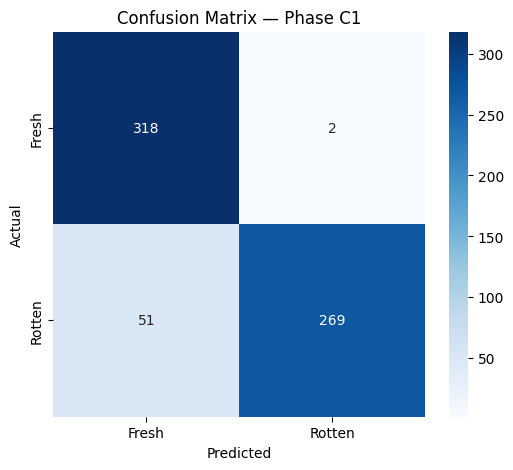

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names,
    cmap='Blues'
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Phase C1")
plt.show()


In [ ]:
DATASET_PATH = "/content/drive/MyDrive/Final_Dataset"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_PATH, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

test_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_PATH, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print("Class Names:", class_names)


Found 12655 files belonging to 2 classes.
Found 640 files belonging to 2 classes.
Class Names: ['Fresh', 'Rotten']


In [ ]:
normalization_layer = layers.Rescaling(1./255)

train_ds = train_ds.map(lambda x, y: (normalization_layer(x), y))
test_ds  = test_ds.map(lambda x, y: (normalization_layer(x), y))

train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds  = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)


In [ ]:
model = keras.Sequential([
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(224,224,3)),
    layers.MaxPooling2D(),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.MaxPooling2D(),

    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dense(1, activation='sigmoid')
])

model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,089 (42.61 MB)

 Trainable params: 11,169,089 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    restore_best_weights=True
)


In [ ]:
EPOCHS = 30  # Upper bound

history_c2 = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)


Epoch 1/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1465s 4s/step - accuracy: 0.7607 - loss: 0.6018 - val_accuracy: 0.8906 - val_loss: 0.2683
Epoch 2/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1252s 3s/step - accuracy: 0.9060 - loss: 0.2271 - val_accuracy: 0.9125 - val_loss: 0.2059
Epoch 3/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1258s 3s/step - accuracy: 0.9328 - loss: 0.1671 - val_accuracy: 0.9219 - val_loss: 0.1926
Epoch 4/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1254s 3s/step - accuracy: 0.9524 - loss: 0.1281 - val_accuracy: 0.9203 - val_loss: 0.1829
Epoch 5/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1241s 3s/step - accuracy: 0.9611 - loss: 0.1057 - val_accuracy: 0.9281 - val_loss: 0.1951
Epoch 6/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1243s 3s/step - accuracy: 0.9696 - loss: 0.0783 - val_accuracy: 0.9281 - val_loss: 0.2307
Epoch 7/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1238s 3s/step - accuracy: 0.9714 - loss: 0.0785 - val_accuracy: 0.9469 - val_loss: 0.1604
Epoch 8/30
396/396 ━━━━━━━━━━━━━━━━━━━━ 1243s 3s/step - accuracy: 0.9823 - loss: 0.0487 - 

In [ ]:
MODEL_DIR = "/content/drive/MyDrive/Fruit_CNN_Models"
os.makedirs(MODEL_DIR, exist_ok=True)

PHASE_C2_MODEL_PATH = MODEL_DIR + "/phaseC2_cnn_early_stop.keras"
model.save(PHASE_C2_MODEL_PATH)

print("✅ Phase C2 model saved")


✅ Phase C2 model saved


In [ ]:
import pickle

PHASE_C2_HISTORY_PATH = MODEL_DIR + "/phaseC2_history.pkl"

with open(PHASE_C2_HISTORY_PATH, "wb") as f:
    pickle.dump(history_c2.history, f)

print("✅ Phase C2 training history saved")


✅ Phase C2 training history saved


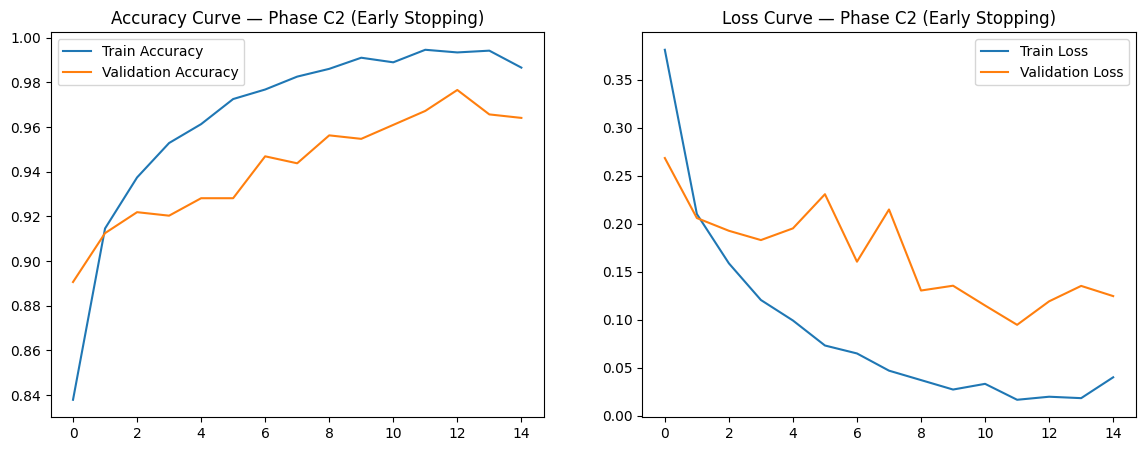

In [ ]:
plt.figure(figsize=(14,5))

# Accuracy
plt.subplot(1,2,1)
plt.plot(history_c2.history['accuracy'], label='Train Accuracy')
plt.plot(history_c2.history['val_accuracy'], label='Validation Accuracy')
plt.legend()
plt.title("Accuracy Curve — Phase C2 (Early Stopping)")

# Loss
plt.subplot(1,2,2)
plt.plot(history_c2.history['loss'], label='Train Loss')
plt.plot(history_c2.history['val_loss'], label='Validation Loss')
plt.legend()
plt.title("Loss Curve — Phase C2 (Early Stopping)")

plt.show()


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


In [ ]:
y_true = np.concatenate([y for x, y in test_ds], axis=0)

y_pred_probs = model.predict(test_ds)
y_pred = (y_pred_probs > 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=class_names))


20/20 ━━━━━━━━━━━━━━━━━━━━ 18s 893ms/step
              precision    recall  f1-score   support

       Fresh       0.96      0.97      0.97       320
      Rotten       0.97      0.96      0.97       320

    accuracy                           0.97       640
   macro avg       0.97      0.97      0.97       640
weighted avg       0.97      0.97      0.97       640



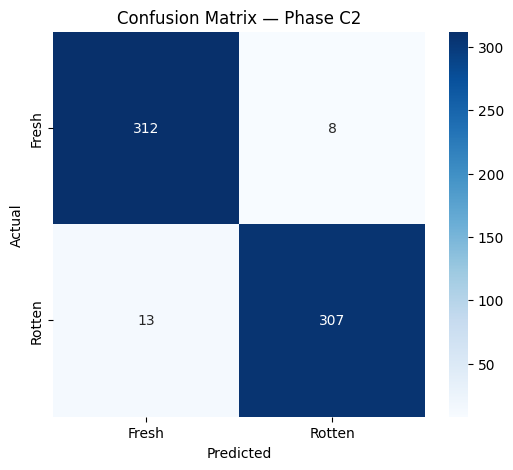

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    xticklabels=class_names,
    yticklabels=class_names,
    cmap='Blues'
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Phase C2")
plt.show()


In [ ]:
from tensorflow import keras
from tensorflow.keras import layers
import tensorflow as tf
import os
import numpy as np
import matplotlib.pyplot as plt


In [ ]:
DATASET_PATH = "/content/drive/MyDrive/Final_Dataset"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_PATH, "train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

test_ds = keras.utils.image_dataset_from_directory(
    os.path.join(DATASET_PATH, "test"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

class_names = train_ds.class_names
print("Class Names:", class_names)


Found 12682 files belonging to 2 classes.
Found 848 files belonging to 2 classes.
Class Names: ['Fresh', 'Rotten']


In [ ]:
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


In [ ]:
train_ds = train_ds.map(lambda x, y: (preprocess_input(x), y))
test_ds  = test_ds.map(lambda x, y: (preprocess_input(x), y))

train_ds = train_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)
test_ds  = test_ds.cache().prefetch(buffer_size=tf.data.AUTOTUNE)


In [ ]:
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False  # VERY IMPORTANT


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
model = keras.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])


In [ ]:
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,081 (9.24 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)


In [ ]:
EPOCHS = 20

history_d1 = model.fit(
    train_ds,
    validation_data=test_ds,
    epochs=EPOCHS,
    callbacks=[early_stopping]
)


Epoch 1/20
396/396 ━━━━━━━━━━━━━━━━━━━━ 800s 2s/step - accuracy: 0.8668 - loss: 0.3173 - val_accuracy: 0.9375 - val_loss: 0.1512
Epoch 2/20
396/396 ━━━━━━━━━━━━━━━━━━━━ 506s 1s/step - accuracy: 0.9725 - loss: 0.0954 - val_accuracy: 0.9609 - val_loss: 0.1013
Epoch 3/20
396/396 ━━━━━━━━━━━━━━━━━━━━ 506s 1s/step - accuracy: 0.9847 - loss: 0.0593 - val_accuracy: 0.9797 - val_loss: 0.0786
Epoch 4/20
396/396 ━━━━━━━━━━━━━━━━━━━━ 525s 1s/step - accuracy: 0.9910 - loss: 0.0416 - val_accuracy: 0.9844 - val_loss: 0.0649
Epoch 5/20
396/396 ━━━━━━━━━━━━━━━━━━━━ 533s 1s/step - accuracy: 0.9946 - loss: 0.0309 - val_accuracy: 0.9875 - val_loss: 0.0559
Epoch 6/20
396/396 ━━━━━━━━━━━━━━━━━━━━ 524s 1s/step - accuracy: 0.9965 - loss: 0.0237 - val_accuracy: 0.9875 - val_loss: 0.0495
Epoch 7/20
396/396 ━━━━━━━━━━━━━━━━━━━━ 503s 1s/step - accuracy: 0.9974 - loss: 0.0186 - val_accuracy: 0.9875 - val_loss: 0.0446
Epoch 8/20
396/396 ━━━━━━━━━━━━━━━━━━━━ 503s 1s/step - accuracy: 0.9978 - loss: 0.0147 - val_accu

In [ ]:
MODEL_DIR = "/content/drive/MyDrive/Fruit_CNN_Models"


In [ ]:
PHASE_D1_MODEL_PATH = MODEL_DIR + "/phaseD1_mobilenet_frozen.keras"
model.save(PHASE_D1_MODEL_PATH)

print("✅ Phase D1 (MobileNetV2 frozen) model saved")


NameError: name 'model' is not defined

In [ ]:
import pickle

PHASE_D1_HISTORY_PATH = MODEL_DIR + "/phaseD1_history.pkl"

with open(PHASE_D1_HISTORY_PATH, "wb") as f:
    pickle.dump(history_d1.history, f)

print("✅ Phase D1 training history saved")


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


In [ ]:
y_true = np.concatenate([y for x, y in test_ds], axis=0)

y_pred_probs = model.predict(test_ds)
y_pred = (y_pred_probs > 0.5).astype(int)

print(classification_report(y_true, y_pred, target_names=class_names))


20/20 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step
              precision    recall  f1-score   support

       Fresh       0.99      1.00      0.99       320
      Rotten       1.00      0.99      0.99       320

    accuracy                           0.99       640
   macro avg       0.99      0.99      0.99       640
weighted avg       0.99      0.99      0.99       640



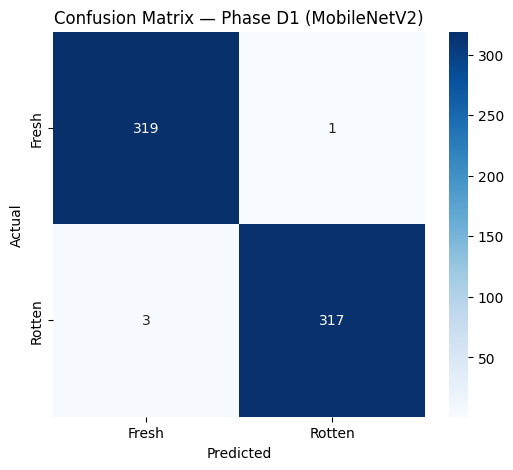

In [ ]:
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names,
    cmap="Blues"
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Phase D1 (MobileNetV2)")
plt.show()


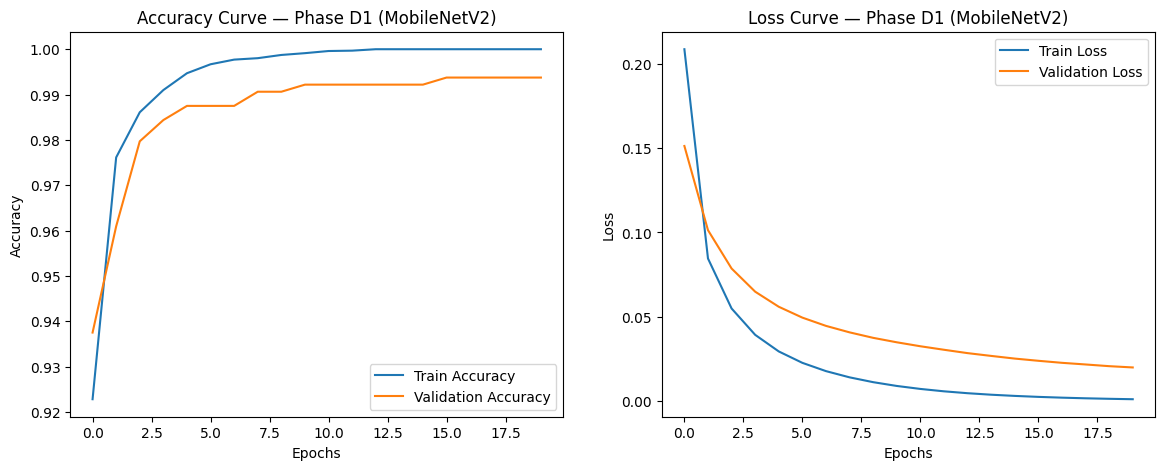

In [ ]:
# ================================
# Plot Accuracy & Loss — Phase D1
# ================================

plt.figure(figsize=(14,5))

# Accuracy curve
plt.subplot(1, 2, 1)
plt.plot(history_d1.history['accuracy'], label='Train Accuracy')
plt.plot(history_d1.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.title("Accuracy Curve — Phase D1 (MobileNetV2)")
plt.legend()

# Loss curve
plt.subplot(1, 2, 2)
plt.plot(history_d1.history['loss'], label='Train Loss')
plt.plot(history_d1.history['val_loss'], label='Validation Loss')
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.title("Loss Curve — Phase D1 (MobileNetV2)")
plt.legend()

plt.show()


In [ ]:
from tensorflow import keras

MODEL_PATH = "/content/drive/MyDrive/Fruit_CNN_Models/phaseD1_mobilenet_frozen.keras"
model = keras.models.load_model(MODEL_PATH)

print("✅ Phase D1 model loaded")


✅ Phase D1 model loaded


In [ ]:
import tensorflow as tf

dummy_input = tf.random.uniform((1, 224, 224, 3))
_ = model(dummy_input)

print("✅ Model built with dummy forward pass")


✅ Model built with dummy forward pass


In [ ]:
last_conv_layer_name = "Conv_1"


In [ ]:
model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,750,277 (10.49 MB)

 Trainable params: 164,097 (641.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 328,196 (1.25 MB)

In [ ]:
# Print all layer names to verify
for layer in model.layers:
    print(layer.name)


In [ ]:
'Conv_1'


'Conv_1'

In [ ]:
base_model = model.layers[0]  # MobileNetV2
print("Base model:", base_model.name)


In [ ]:
import tensorflow as tf
import numpy as np
import cv2
import matplotlib.pyplot as plt


In [ ]:
last_conv_layer_name = "Conv_1"
last_conv_layer = base_model.get_layer(last_conv_layer_name)


In [ ]:
from tensorflow import keras
import tensorflow as tf

MODEL_PATH = "/content/drive/MyDrive/Fruit_CNN_Models/phaseD1_mobilenet_frozen.keras"
loaded_model = keras.models.load_model(MODEL_PATH)

print("✅ Model loaded")


✅ Model loaded


In [ ]:
# Backbone (MobileNetV2)
base_model = loaded_model.layers[0]

# Classification head layers
gap_layer   = loaded_model.layers[1]
dense_layer = loaded_model.layers[2]
out_layer   = loaded_model.layers[3]


In [ ]:
inputs = keras.Input(shape=(224, 224, 3))

x = base_model(inputs, training=False)
x = gap_layer(x)
x = dense_layer(x)
outputs = out_layer(x)

functional_model = keras.Model(inputs, outputs)

print("✅ Functional model rebuilt successfully")


✅ Functional model rebuilt successfully


In [ ]:
last_conv_layer_name = "Conv_1"

grad_model = keras.Model(
    inputs=functional_model.input,
    outputs=[
        base_model.get_layer(last_conv_layer_name).output,
        functional_model.output
    ]
)

print("✅ Grad-CAM model created (SAFE)")


✅ Grad-CAM model created (SAFE)


In [ ]:
import numpy as np

def make_gradcam_heatmap(img_array, grad_model):
    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        loss = predictions[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap)

    return heatmap.numpy()


In [ ]:
import os

# ================================
# Correct image directory (ROOT of MyDrive)
# ================================

IMAGE_DIR = "/content/drive/MyDrive"

image_paths = [
    os.path.join(IMAGE_DIR, "aiapple.jpg"),
    os.path.join(IMAGE_DIR, "aibanana.webp"),
    os.path.join(IMAGE_DIR, "aiorange.png"),
    os.path.join(IMAGE_DIR, "applebad.jpg"),
    os.path.join(IMAGE_DIR, "apple-gone-bad.jpg"),
]


In [ ]:
for p in image_paths:
    print(p, "->", os.path.exists(p))


/content/drive/MyDrive/aiapple.jpg -> True
/content/drive/MyDrive/aibanana.webp -> True
/content/drive/MyDrive/aiorange.png -> True
/content/drive/MyDrive/applebad.jpg -> True
/content/drive/MyDrive/apple-gone-bad.jpg -> True


In [ ]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import numpy as np
import cv2
import matplotlib.pyplot as plt


In [ ]:
def run_gradcam_on_image(img_path, grad_model):
    # Load & preprocess image
    img = load_img(img_path, target_size=(224, 224))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    img_array = preprocess_input(img_array)

    # Generate heatmap
    heatmap = make_gradcam_heatmap(img_array, grad_model)

    # Load original image for overlay
    orig = cv2.imread(img_path)
    orig = cv2.resize(orig, (224, 224))

    heatmap = cv2.resize(heatmap, (224, 224))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    superimposed = cv2.addWeighted(orig, 0.6, heatmap, 0.4, 0)

    # Display
    plt.figure(figsize=(5,5))
    plt.imshow(cv2.cvtColor(superimposed, cv2.COLOR_BGR2RGB))
    plt.title(img_path.split("/")[-1])
    plt.axis("off")
    plt.show()


In [ ]:
import os

# List everything in MyDrive
os.listdir("/content/drive/MyDrive")


['Colab Notebooks',
 'IMG-20240708-WA0001.jpg',
 'Classroom',
 'PRACT 4.docx',
 'Screenshot (8).png',
 'impact-of-internet-of-things-on-society-IJERTCONV5IS03020.pdf',
 'IMG-20241010-WA0035.jpg',
 'rakshit_ladda.pdf',
 'SAMEEKSHA-IOT (2).pptx',
 'SAMEEKSHA-IOT (1).pptx',
 'SAMEEKSHA-IOT.pptx',
 'Copy of ELECTRICALAPPROVAL.gdoc',
 'Screenshot 2024-11-08 113926.png',
 'eee assingment.pdf',
 'Document from Rakshit Ladda.pdf',
 'BT24ECE063. RAKSHIT LADDA.pdf',
 'SAMKEESHA IOT funal paper.pdf',
 'Screenshot_2025-01-19-21-04-30-312_com.phonepe.app.jpg',
 'Screenshot_2025-01-25-10-17-57-042_com.miui.gallery.jpg',
 'Screenshot_2025-04-19-16-14-39-959_com.phonepe.app.jpg',
 'Untitled spreadsheet.gsheet',
 'RAKSHIT_LADDA(BT24CSD066).png',
 'BT24CSD066(RAKSHIT LADDA).png',
 'RAKSHIT LADDA(BT24CSD066) LOGO.jpg',
 ' BRANCH_CHANGE_APPLICATION.gdoc',
 'BT24CSD066(RAKSHIT LADDA)MINDEASE.pdf',
 'Screenshot 2025-09-05 121312.png',
 'TF_2025_BROCHURE EVE1.pdf',
 '50_Startups (1).csv.gsheet',
 '50_Startup

In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


In [ ]:
# Build MobileNetV2 backbone
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)
base_model.trainable = False

# Build classifier (same as training)
inputs = keras.Input(shape=(224, 224, 3))
x = base_model(inputs, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(128, activation="relu")(x)
outputs = layers.Dense(1, activation="sigmoid")(x)

gradcam_model = keras.Model(inputs, outputs)


In [ ]:
# Load weights from trained model
gradcam_model.load_weights(
    "/content/drive/MyDrive/Fruit_CNN_Models/phaseD1_mobilenet_frozen.keras"
)

print("✅ Weights loaded correctly")


✅ Weights loaded correctly


In [ ]:
last_conv_layer = base_model.get_layer("Conv_1")

grad_model = keras.Model(
    inputs=gradcam_model.input,
    outputs=[last_conv_layer.output, gradcam_model.output]
)

print("✅ Grad-CAM model ready")


✅ Grad-CAM model ready


In [ ]:
import numpy as np

def make_gradcam_heatmap(img_array, grad_model):
    with tf.GradientTape() as tape:
        conv_outputs, preds = grad_model(img_array)
        loss = preds[:, 0]

    grads = tape.gradient(loss, conv_outputs)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    conv_outputs = conv_outputs[0]
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)

    heatmap = tf.maximum(heatmap, 0)
    heatmap /= tf.reduce_max(heatmap) + 1e-8
    return heatmap.numpy()


In [ ]:
import tensorflow as tf
from tensorflow import keras

model = keras.models.load_model(
    "/content/drive/MyDrive/Fruit_CNN_Models/phaseD1_mobilenet_frozen.keras"
)

print("✅ Model loaded")


✅ Model loaded


In [ ]:
# MobileNetV2 backbone is the first layer
base_model = model.layers[0]

# Last conv layer in MobileNetV2
last_conv_layer = base_model.get_layer("Conv_1")

print("✅ Last conv layer found:", last_conv_layer.name)


✅ Last conv layer found: Conv_1


In [ ]:
feature_extractor = keras.Model(
    inputs=base_model.input,
    outputs=last_conv_layer.output
)


In [ ]:
import numpy as np
import tensorflow as tf
from tensorflow import keras # Ensure keras is imported here for Model

def make_gradcam_heatmap(img_tensor, base_model, classifier_head):
    # Create a feature extractor model that goes from the base_model's input
    # to the output of its last convolutional layer ('Conv_1').
    # This ensures the internal graph of base_model is correctly used when processing img_tensor.
    feature_extractor = keras.Model(
        inputs=base_model.input,
        outputs=base_model.get_layer("Conv_1").output
    )

    with tf.GradientTape() as tape:
        # The img_tensor is processed by the feature_extractor to get the conv_outputs.
        # training=True is passed to ensure Batch Normalization layers in MobileNetV2
        # behave as they would during training, allowing gradients to flow correctly.
        conv_outputs = feature_extractor(img_tensor, training=True)
        tape.watch(conv_outputs)

        # The output of the feature_extractor (conv_outputs) is then passed to the classifier_head
        # to get the final predictions.
        preds = classifier_head(conv_outputs)
        loss = preds[:, 0] # Assuming binary classification, get the score for the positive class

    # Compute gradients of the predicted class with respect to the last convolutional layer's output.
    grads = tape.gradient(loss, conv_outputs)

    if grads is None:
        print("Warning: Gradients are None. This might indicate a non-differentiable path or an issue with model construction.")
        # Return a small heatmap to avoid further errors, or handle appropriately
        return np.zeros((7, 7))

    # Pool the gradients to get a single importance value per filter.
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))

    # Multiply each channel in the convolutional output by its corresponding pooled gradient
    # and sum across channels to get the raw heatmap.
    conv_outputs = conv_outputs[0] # Get the first (and only) image's feature map from the batch
    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)

    # Normalize the heatmap to a range of 0 to 1 for visualization.
    heatmap = tf.maximum(heatmap, 0) / (tf.reduce_max(heatmap) + 1e-8) # Add epsilon to avoid division by zero

    return heatmap.numpy()

print("✅ make_gradcam_heatmap function updated for robust base_model usage.")

✅ make_gradcam_heatmap function updated for robust base_model usage.


In [ ]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import cv2
import matplotlib.pyplot as plt
import os


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step


/usr/local/lib/python3.12/dist-packages/keras/src/models/functional.py:241: UserWarning: The structure of `inputs` doesn't match the expected structure.
Expected: ['input_layer_2']
Received: inputs=Tensor(shape=(1, 224, 224, 3))
  warnings.warn(msg)


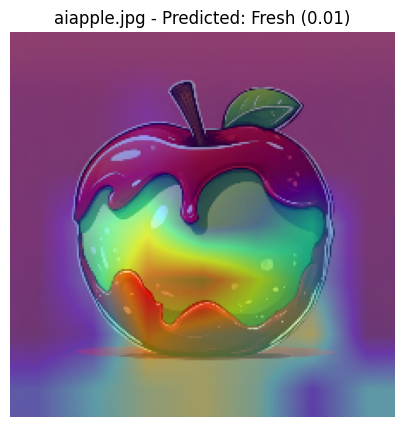

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step


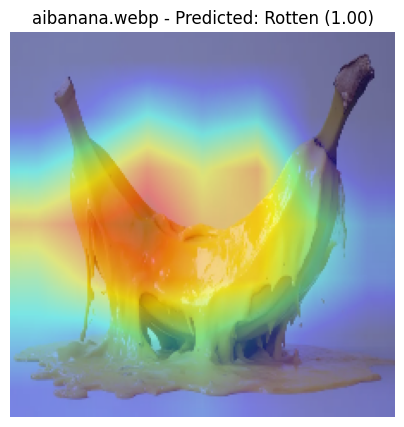

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step


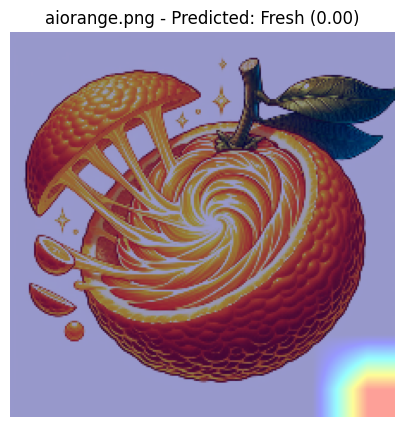

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step


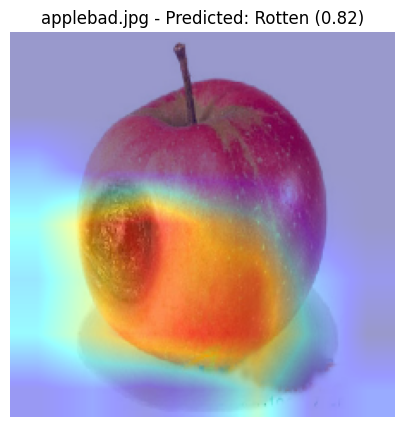

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step


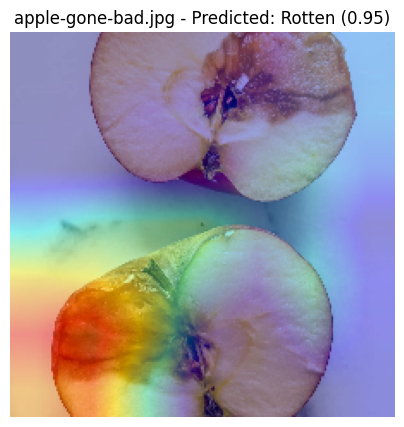

In [ ]:
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import cv2
import matplotlib.pyplot as plt
import os

IMAGE_DIR = "/content/drive/MyDrive"

image_files = [
    "aiapple.jpg",
    "aibanana.webp",
    "aiorange.png",
    "applebad.jpg",
    "apple-gone-bad.jpg"
]

# Ensure class_names is defined (it should be from previous cells, but good practice)
if 'class_names' not in locals():
    # Fallback if class_names isn't globally available for some reason
    class_names = ['Fresh', 'Rotten'] # Assuming Fresh is 0, Rotten is 1

for fname in image_files:
    img_path = os.path.join(IMAGE_DIR, fname)

    # Load image
    img = load_img(img_path, target_size=(224,224))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    processed_img_array = preprocess_input(img_array)

    # Make prediction to determine the predicted class
    # Use the full_model_loaded for prediction, as it's the Sequential model trained
    prediction_raw = full_model_loaded.predict(processed_img_array)
    predicted_class_index = int(np.round(prediction_raw[0][0])) # 0 for Fresh, 1 for Rotten

    # Generate Grad-CAM heatmap using the manual function
    heatmap = make_gradcam_heatmap(processed_img_array, base_model, classifier_head)

    # Overlay heatmap on original image
    original = cv2.imread(img_path)
    original = cv2.resize(original, (224,224))

    # Resize heatmap to original image size and apply colormap
    heatmap = cv2.resize(heatmap, (224,224))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    # Combine original image with heatmap
    overlay = cv2.addWeighted(original, 0.6, heatmap, 0.4, 0)

    plt.figure(figsize=(5,5))
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f"{fname} - Predicted: {class_names[predicted_class_index]} ({prediction_raw[0][0]:.2f})")
    plt.axis("off")
    plt.show()

In [ ]:
import os
import random

TEST_DIR = "/content/drive/MyDrive/Final_Dataset/test"
FRESH_DIR = os.path.join(TEST_DIR, "Fresh")
ROTTEN_DIR = os.path.join(TEST_DIR, "Rotten")


In [ ]:
fresh_images = os.listdir(FRESH_DIR)
rotten_images = os.listdir(ROTTEN_DIR)

print("Total Fresh test images:", len(fresh_images))
print("Total Rotten test images:", len(rotten_images))


Total Fresh test images: 416
Total Rotten test images: 432


In [ ]:
random.seed(42)

selected_fresh = random.sample(fresh_images, 15)
selected_rotten = random.sample(rotten_images, 15)


In [ ]:
selected_test_images = []

for img in selected_fresh:
    selected_test_images.append(os.path.join(FRESH_DIR, img))

for img in selected_rotten:
    selected_test_images.append(os.path.join(ROTTEN_DIR, img))

print("Total selected test images:", len(selected_test_images))


Total selected test images: 30


In [ ]:
import pandas as pd

df = pd.DataFrame(selected_test_images, columns=["image_path"])
df.to_csv("/content/drive/MyDrive/gradcam_test_image_list.csv", index=False)

print("✅ Saved selected test image list")


✅ Saved selected test image list


In [ ]:
import os

OUTPUT_DIR = "/content/drive/MyDrive/gradcam_test_results"

os.makedirs(OUTPUT_DIR, exist_ok=True)
print("✅ Output directory ready:", OUTPUT_DIR)


✅ Output directory ready: /content/drive/MyDrive/gradcam_test_results


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

class_names = ["Fresh", "Rotten"]

for img_path in selected_test_images:

    # ----------------------------
    # 1. Load & preprocess image
    # ----------------------------
    img = load_img(img_path, target_size=(224,224))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    processed_img = preprocess_input(img_array)

    # ----------------------------
    # 2. Predict using Phase D model
    # ----------------------------
    prediction = full_model_loaded.predict(processed_img, verbose=0)
    pred_prob = prediction[0][0]
    pred_class = int(np.round(pred_prob))
    pred_label = class_names[pred_class]

    # ----------------------------
    # 3. Generate Grad-CAM heatmap
    # ----------------------------
    heatmap = make_gradcam_heatmap(
        processed_img,
        base_model,
        classifier_head
    )

    # ----------------------------
    # 4. Overlay heatmap
    # ----------------------------
    original = cv2.imread(img_path)
    original = cv2.resize(original, (224,224))

    heatmap = cv2.resize(heatmap, (224,224))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    overlay = cv2.addWeighted(original, 0.6, heatmap, 0.4, 0)

    # ----------------------------
    # 5. Save result
    # ----------------------------
    img_name = os.path.basename(img_path)
    save_path = os.path.join(
        OUTPUT_DIR,
        f"{pred_label}_{pred_prob:.2f}_{img_name}"
    )

    cv2.imwrite(save_path, overlay)

    # ----------------------------
    # 6. (Optional) Display
    # ----------------------------
    plt.figure(figsize=(4,4))
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f"{pred_label} ({pred_prob:.2f})")
    plt.axis("off")
    plt.show()

print("✅ Grad-CAM completed for selected test images")


Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import random

random.seed(123)   # change seed
selected_fresh = random.sample(fresh_images, 5)
selected_rotten = random.sample(rotten_images, 5)

selected_images = selected_fresh + selected_rotten


In [ ]:
# Directories
FRESH_DIR = "/content/drive/MyDrive/Final_Dataset/test/Fresh"
ROTTEN_DIR = "/content/drive/MyDrive/Final_Dataset/test/Rotten"

import random
random.seed(123)

# Sample filenames
selected_fresh = random.sample(os.listdir(FRESH_DIR), 5)
selected_rotten = random.sample(os.listdir(ROTTEN_DIR), 5)

# ✅ Build FULL paths (THIS IS THE FIX)
selected_images = (
    [os.path.join(FRESH_DIR, img) for img in selected_fresh] +
    [os.path.join(ROTTEN_DIR, img) for img in selected_rotten]
)

print("Total selected images:", len(selected_images))



Total selected images: 10


In [ ]:
for p in selected_images:
    print(p, "→", os.path.exists(p))


/content/drive/MyDrive/Final_Dataset/test/Fresh/FreshApple_FreshApple (119).jpg → True
/content/drive/MyDrive/Final_Dataset/test/Fresh/FreshGuava_FreshGuava (63).jpg → True
/content/drive/MyDrive/Final_Dataset/test/Fresh/FreshBanana_FreshBanana (74).jpg → True
/content/drive/MyDrive/Final_Dataset/test/Fresh/FreshPomegranate_FreshPomegranate (180).jpg → True
/content/drive/MyDrive/Final_Dataset/test/Fresh/FreshOrange_FreshOrange (191).jpg → True
/content/drive/MyDrive/Final_Dataset/test/Rotten/RottenGuava_RottenGuava (112).jpg → True
/content/drive/MyDrive/Final_Dataset/test/Rotten/RottenBanana_RottenBanana (194).jpg → True
/content/drive/MyDrive/Final_Dataset/test/Rotten/RottenStrawberry_RottenStrawberry (54).jpg → True
/content/drive/MyDrive/Final_Dataset/test/Rotten/RottenApple_RottenApple (2).jpg → True
/content/drive/MyDrive/Final_Dataset/test/Rotten/RottenJujube_RottenJujube (186).jpg → True


Total selected images: 10
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 137ms/step


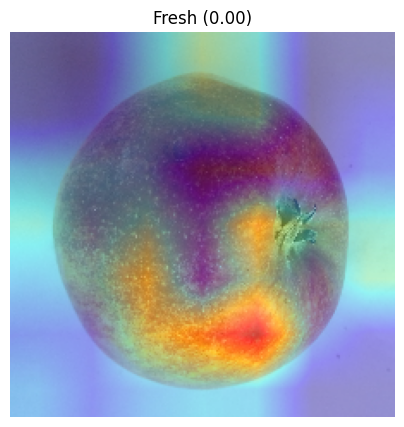

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step


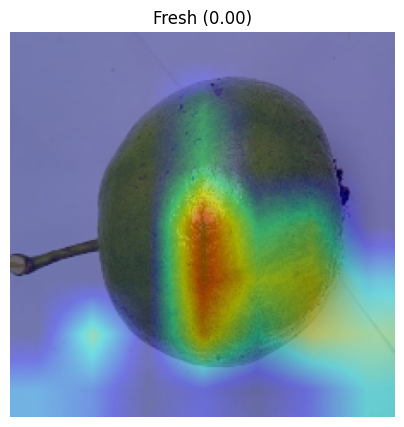

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 155ms/step


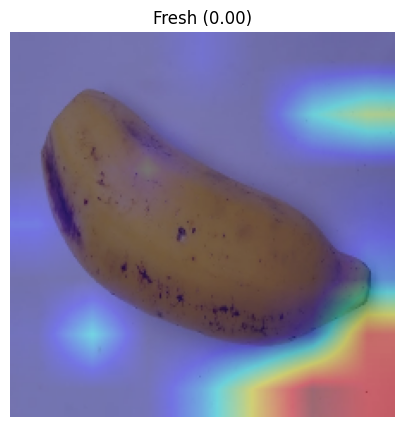

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 167ms/step


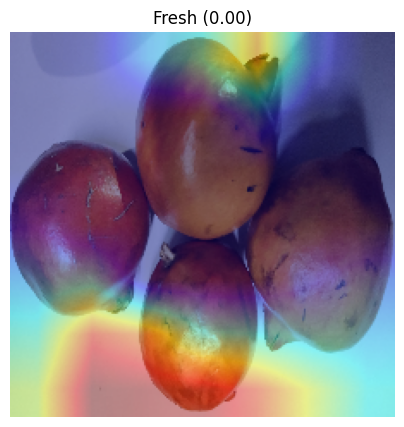

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 165ms/step


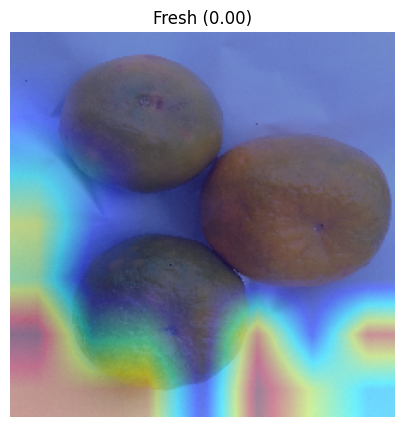

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step


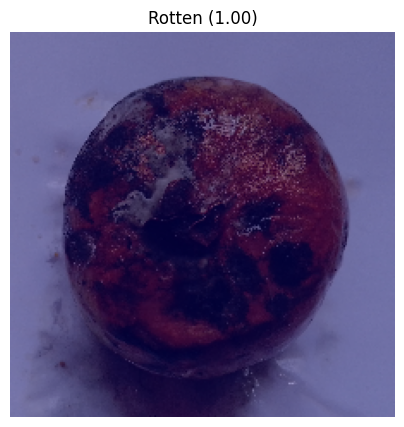

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step


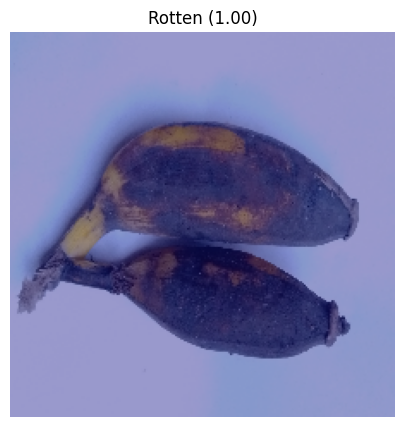

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step


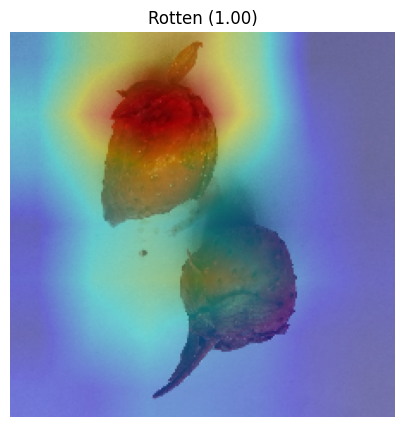

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step


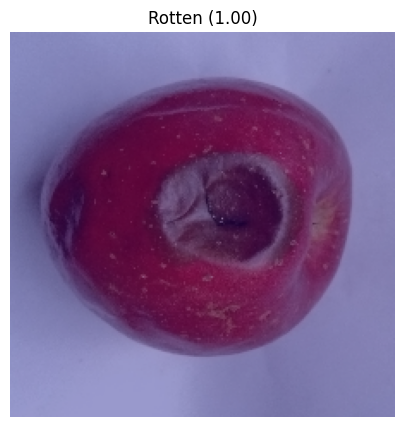

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step


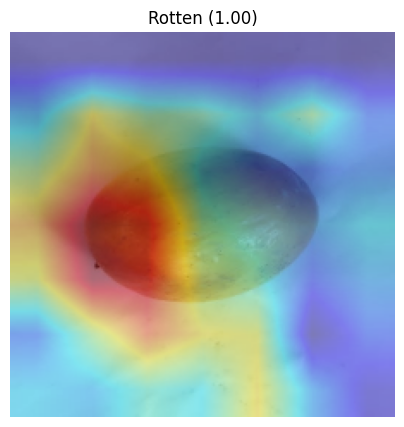

✅ Grad-CAM completed for new random test images


In [ ]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import os

# Safety check
print(f"Total selected images: {len(selected_images)}")

for img_path in selected_images:
    # -----------------------------
    # Load & preprocess image
    # -----------------------------
    img = load_img(img_path, target_size=(224, 224))
    img_array = img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0)
    processed_img = preprocess_input(img_array)

    # -----------------------------
    # Prediction
    # -----------------------------
    pred = full_model_loaded.predict(processed_img)
    pred_prob = float(pred[0][0])
    pred_class = "Rotten" if pred_prob >= 0.5 else "Fresh"

    # -----------------------------
    # Grad-CAM
    # -----------------------------
    heatmap = make_gradcam_heatmap(
        processed_img,
        base_model=base_model,
        classifier_head=classifier_head
    )

    # -----------------------------
    # Overlay heatmap
    # -----------------------------
    original = cv2.imread(img_path)
    original = cv2.resize(original, (224, 224))

    heatmap = cv2.resize(heatmap, (224, 224))
    heatmap = np.uint8(255 * heatmap)
    heatmap = cv2.applyColorMap(heatmap, cv2.COLORMAP_JET)

    overlay = cv2.addWeighted(original, 0.6, heatmap, 0.4, 0)

    # -----------------------------
    # Display
    # -----------------------------
    plt.figure(figsize=(5, 5))
    plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
    plt.title(f"{pred_class} ({pred_prob:.2f})")
    plt.axis("off")
    plt.show()

print("✅ Grad-CAM completed for new random test images")


In [ ]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras import layers

# Use the trained Phase D model
# full_model_loaded already exists

# Create an explicit Input layer matching the model's expected input shape
input_tensor = layers.Input(shape=(224, 224, 3))

# Extract MobileNetV2 backbone (which is the first layer of full_model_loaded)
base_model = full_model_loaded.layers[0]

# Pass the explicit input tensor through the base_model to get its output tensor
base_model_output_tensor = base_model(input_tensor)

# Freeze it (important for feature extraction)
base_model.trainable = False

# Create feature extractor model using the explicit input and base_model's output
feature_extractor = Model(
    inputs=input_tensor,
    outputs=base_model_output_tensor
)

print("✅ Feature extractor ready")
print("Feature shape:", feature_extractor.output_shape)

✅ Feature extractor ready
Feature shape: (None, 7, 7, 1280)


In [ ]:
import numpy as np
from tensorflow.keras.layers import GlobalAveragePooling2D

# Global Average Pooling layer
gap_layer = GlobalAveragePooling2D()

def extract_features(image_batch):
    """
    image_batch: (N, 224, 224, 3)
    returns: (N, 1280)
    """
    feature_maps = feature_extractor(image_batch, training=False)
    feature_vectors = gap_layer(feature_maps)
    return feature_vectors.numpy()

print("✅ Feature vector extractor ready")


✅ Feature vector extractor ready


In [ ]:
import os
from tensorflow.keras.preprocessing.image import load_img, img_to_array
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input
import random

TRAIN_FRESH_DIR = "/content/drive/MyDrive/Final_Dataset/train/Fresh"
TRAIN_ROTTEN_DIR = "/content/drive/MyDrive/Final_Dataset/train/Rotten"

# Sample background images
random.seed(42)

bg_fresh = random.sample(os.listdir(TRAIN_FRESH_DIR), 25)
bg_rotten = random.sample(os.listdir(TRAIN_ROTTEN_DIR), 25)

background_paths = (
    [os.path.join(TRAIN_FRESH_DIR, f) for f in bg_fresh] +
    [os.path.join(TRAIN_ROTTEN_DIR, f) for f in bg_rotten]
)

def load_images(paths):
    imgs = []
    for p in paths:
        img = load_img(p, target_size=(224,224))
        arr = img_to_array(img)
        arr = preprocess_input(arr)
        imgs.append(arr)
    return np.array(imgs)

background_images = load_images(background_paths)

# Extract background features
background_features = extract_features(background_images)

print("✅ SHAP background prepared:", background_features.shape)


✅ SHAP background prepared: (50, 1280)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Prepare training data for surrogate model
train_paths = (
    [os.path.join(TRAIN_FRESH_DIR, f) for f in bg_fresh] +
    [os.path.join(TRAIN_ROTTEN_DIR, f) for f in bg_rotten]
)

# Labels: Fresh = 0, Rotten = 1
y_train = np.array([0]*25 + [1]*25)

# Extract CNN features
X_train = extract_features(load_images(train_paths))

print("Surrogate training data shape:", X_train.shape)


Surrogate training data shape: (50, 1280)


In [ ]:
from sklearn.linear_model import LogisticRegression

# Prepare training data for surrogate model
train_paths = (
    [os.path.join(TRAIN_FRESH_DIR, f) for f in bg_fresh] +
    [os.path.join(TRAIN_ROTTEN_DIR, f) for f in bg_rotten]
)

# Labels: Fresh = 0, Rotten = 1
y_train = np.array([0]*25 + [1]*25)

# Extract CNN features
X_train = extract_features(load_images(train_paths))

# Train the surrogate model
surrogate_model = LogisticRegression(random_state=42)
surrogate_model.fit(X_train, y_train)

print("Surrogate training data shape:", X_train.shape)
print("✅ Surrogate model trained and ready.")

Surrogate training data shape: (50, 1280)
✅ Surrogate model trained and ready.


In [ ]:
# Use a small subset of test images (e.g., 5 images)
shap_test_paths = selected_images[:5]  # reuse Grad-CAM images

X_test = extract_features(load_images(shap_test_paths))

print("SHAP test features shape:", X_test.shape)


SHAP test features shape: (5, 1280)


In [ ]:
import shap

# Create SHAP explainer
explainer = shap.Explainer(
    surrogate_model,
    background_features
)

# Compute SHAP values
shap_values = explainer(X_test)

print("✅ SHAP values computed")

✅ SHAP values computed


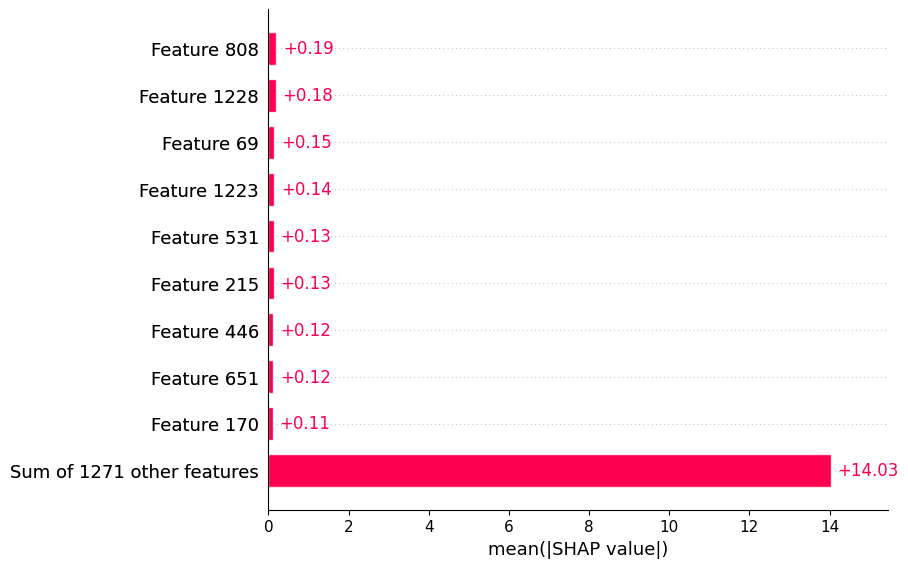

In [ ]:
shap.plots.bar(shap_values)


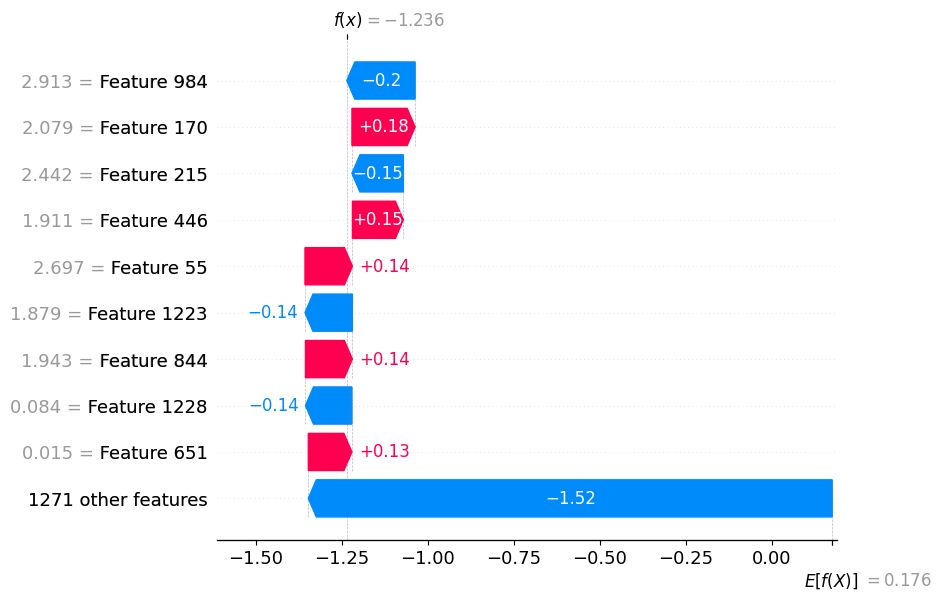

In [ ]:
shap.plots.waterfall(shap_values[0])


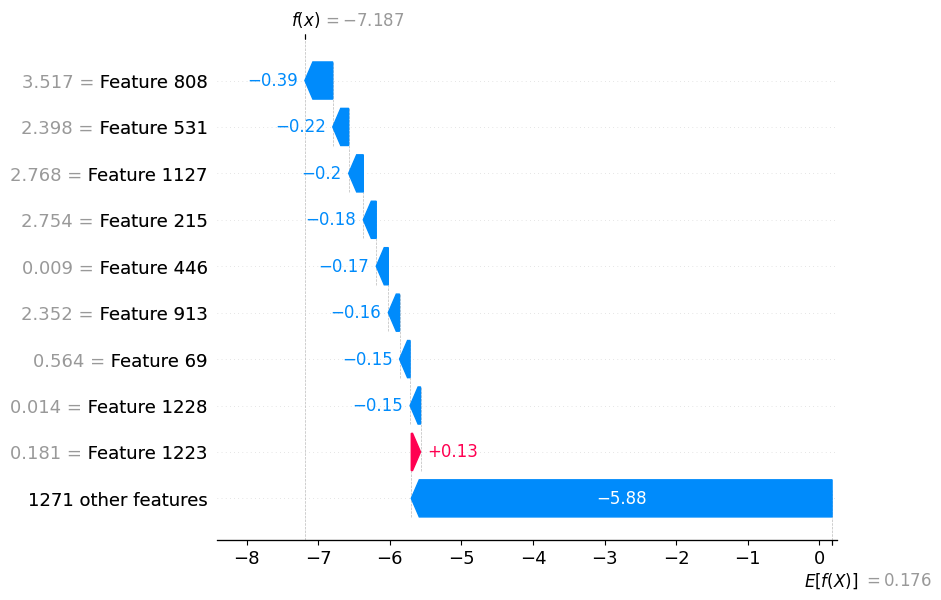

In [ ]:
shap.plots.waterfall(shap_values[1])
